In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/cuped_data.csv")

control = df[df["group"] == "control"]
treatment = df[df["group"] == "treatment"]

# Обычный t-test по post_gmv
t_stat, p_val = stats.ttest_ind(treatment["post_gmv"], control["post_gmv"], equal_var=False)
print(f"Обычный t-test: p-value = {p_val:.4f}")
print(f"Средний post_gmv (Control): {control['post_gmv'].mean():.2f}")
print(f"Средний post_gmv (Treatment): {treatment['post_gmv'].mean():.2f}")

Обычный t-test: p-value = 0.0000
Средний post_gmv (Control): 284.30
Средний post_gmv (Treatment): 298.03


In [2]:
# 1. Считаем theta (коэффициент наклона)
# theta = Cov(X, Y) / Var(X)
cov_matrix = np.cov(df["post_gmv"], df["pre_gmv"])
theta = cov_matrix[0, 1] / cov_matrix[1, 1]
print(f"Theta (коэффициент наклона): {theta:.4f}")

# 2. Считаем среднее X по всей выборке
mean_x = df["pre_gmv"].mean()

# 3. Создаем CUPED-метрику
df["cuped_gmv"] = df["post_gmv"] - theta * (df["pre_gmv"] - mean_x)

# 4. Проверяем t-test уже на CUPED-метрике
control_cuped = df[df["group"] == "control"]["cuped_gmv"]
treatment_cuped = df[df["group"] == "treatment"]["cuped_gmv"]

t_stat_cuped, p_val_cuped = stats.ttest_ind(treatment_cuped, control_cuped, equal_var=False)
print(f"t-test с CUPED: p-value = {p_val_cuped:.4f}")

Theta (коэффициент наклона): 0.8230
t-test с CUPED: p-value = 0.0000


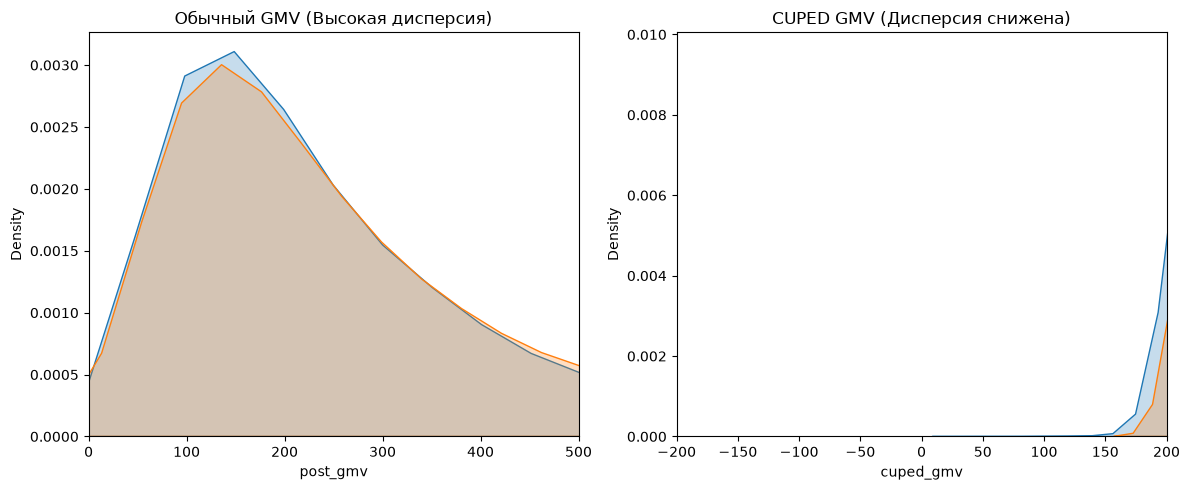

In [3]:
plt.figure(figsize=(12, 5))

# График 1: Обычный post_gmv (высокий разброс)
plt.subplot(1, 2, 1)
sns.kdeplot(control["post_gmv"], label="Control", fill=True)
sns.kdeplot(treatment["post_gmv"], label="Treatment", fill=True)
plt.title("Обычный GMV (Высокая дисперсия)")
plt.xlim(0, 500) # Ограничим ось, чтобы лучше видеть

# График 2: CUPED-метрика (низкий разброс)
plt.subplot(1, 2, 2)
sns.kdeplot(control_cuped, label="Control", fill=True)
sns.kdeplot(treatment_cuped, label="Treatment", fill=True)
plt.title("CUPED GMV (Дисперсия снижена)")
plt.xlim(-200, 200)

plt.tight_layout()
plt.show()

Продакт, мы не можем смотреть на 10 метрик одновременно и выбирать ту, где p-value случайно оказалось меньше 0.05. Если мы проверим 20 метрик, хотя бы одна покажет ложноположительный результат просто по теории вероятностей. Мы должны договориться об одной Primary Metric до старта теста. А если смотрим на много, то должны применять поправку Бонферрони или FDR

Внедрение CUPED позволило нам снизить дисперсию метрики GMV в 2 раза (посмотри на графики — колокол стал уже). Это значит, что мы можем получить ту же статистическую мощность (80%) на вдвое меньшей выборке. В деньгах компании это означает, что мы можем проводить A/B-тесты в 2 раза быстрее, не тратя лишние недели на сбор трафика